# Simulation of the Convolution of Neutron spectrum and Chopper opening function
Create increasingly difficult neutron spectra  
Create increasingly difficult chopper functions  
Convolute the functions  
Compare the outputs of the convoluted functions to the output of approximations

In [65]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import matplotlib.colors as mcolors
import math
import scipy as scp

from tof_helper_functions.tof_framework import RawTOFPointList, RebinnedTOFPointList
from tof_helper_functions.tof_simulation_objects import Chopper, Detector
#plt.style.use('stylesheet.mplstyle')

In [66]:
def maxwell(x,a,sigma):
    return a * x**2 / sigma**3 *np.exp(-(x)**2/(2*sigma**2))

In [67]:
# generate maxwellian spectrum N(bin)
n = 4000
n_max =  n-1
a = 1000000
sigma = 400

print(f"mean = {2*a*sigma}")

x_list = np.linspace(0,n_max,n)
maxwell_signal_list = maxwell(x_list, a, sigma)

mean = 800000000


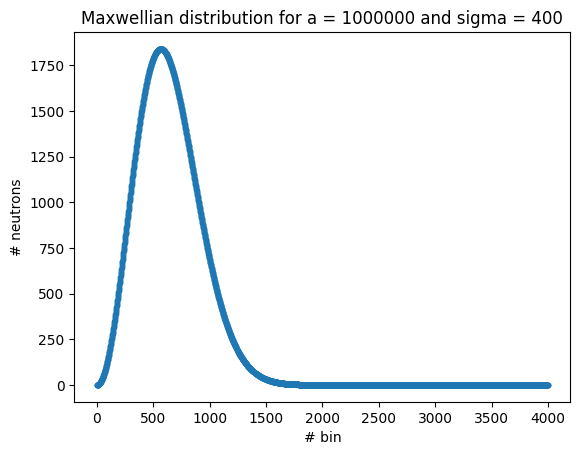

Text(0.5, 1.0, 'Incoming neutron spectrum')

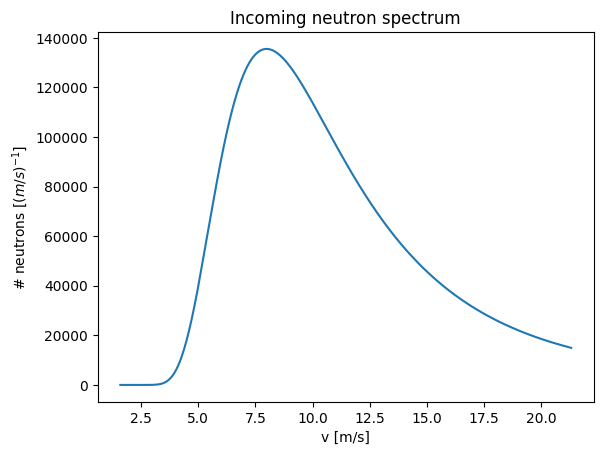

In [68]:
# feed the maxwellian signal into the TOF framework
rawTOF_maxwellian = RawTOFPointList(maxwell_signal_list, 
                         s=631, 
                         label = "Poissonian")
v_max = 18.5
v_min = 3.5
v_step = 0.05
rebinnedTOF_maxwellian = RebinnedTOFPointList(rawTOF_maxwellian,
                                   v_min = v_min,
                                   v_max = v_max,
                                   v_step = v_step,
                                   label = "Rebinned Maxwellian")


plt.plot(rawTOF_maxwellian.bin_number, rawTOF_maxwellian.N_bin, marker='.') 
plt.xlabel("# bin")
plt.ylabel("# neutrons")
plt.title(f"Maxwellian distribution for a = {a} and sigma = {sigma}")
#plt.legend()
plt.show()

plt.clf()
plt.plot(rawTOF_maxwellian.v[300:None], rawTOF_maxwellian.N_v[300:None])
plt.xlabel("v [m/s]")
plt.ylabel(r"# neutrons [$(m/s)^{-1}$]")
plt.title("Incoming neutron spectrum")

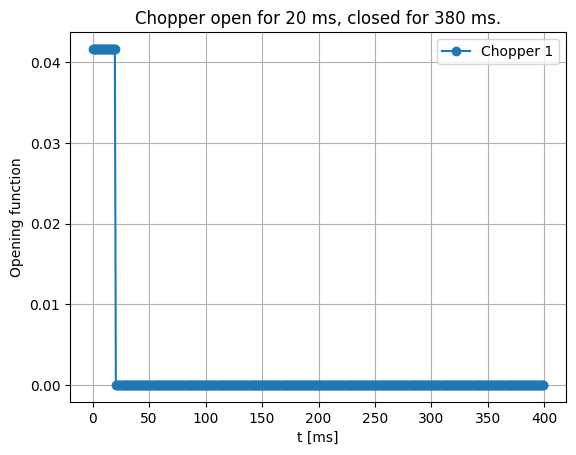

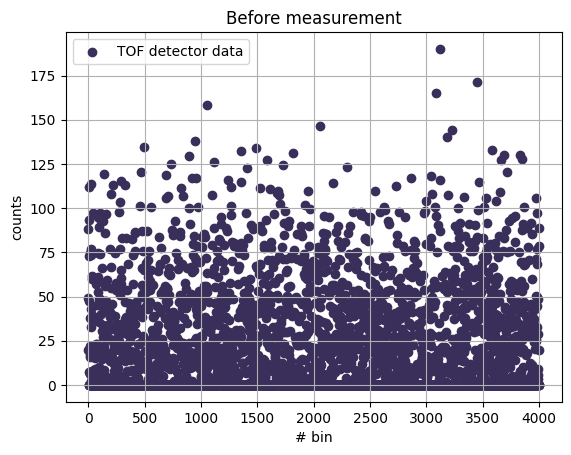

In [69]:
# chopper cycle open for 20 m and close for 380 ms
chopper_cycle_time_ms = 400
chopper_open_time_ms = 20
chopper1 = Chopper("Chopper 1", num_chop=466, t_open_ms=chopper_open_time_ms, t_close_ms=chopper_cycle_time_ms-chopper_open_time_ms)
chopper1.renormalize_opening_function()
chopper1.plot()

# detector
detector1 = Detector(num_bins=4000, 
                     s_mm=639, 
                     do_cycle=False,
                     do_gaussian_noise=True,
                     sigma = 50)
detector1.plot(title="Before measurement")
detector1.measure(rawTOF_maxwellian, chopper1)


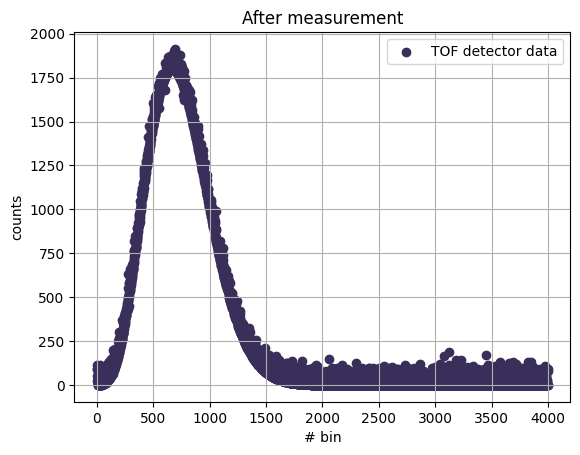

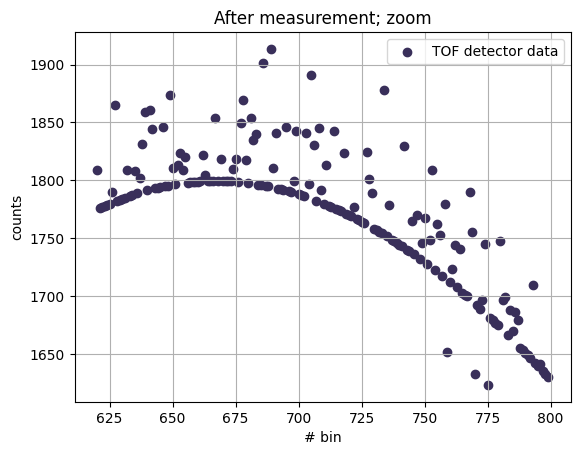

In [70]:
detector1.plot(title="After measurement", cut1=None, cut2=None)
detector1.plot(title="After measurement; zoom", cut1=620, cut2=800)

In [71]:
# analyze convoluted spectrum
t_convolution_offset = chopper_open_time_ms / 2.0
t_convolution_offset_err = (chopper1.t_open_ms - 0.0) * 0.6827 *0.5
#t_convolution_offset_err = 0

rawTOF_maxwellian_convoluted = RawTOFPointList(detector1.data, 
                         s=631, 
                         label = "Convoluted",
                         convolution_t=t_convolution_offset,
                         convolution_t_err=t_convolution_offset_err)

rebinnedTOF_maxwellian_convoluted = RebinnedTOFPointList(rawTOF_maxwellian_convoluted,
                                   v_min = v_min,
                                   v_max = v_max,
                                   v_step = v_step,
                                   label = "Rebinned convoluted")

rawTOF_maxwellian_convoluted_uncorrected = RawTOFPointList(detector1.data, 
                         s=631, 
                         label = "Convoluted, no correction")

rebinnedTOF_maxwellian_convoluted_uncorrected = RebinnedTOFPointList(rawTOF_maxwellian_convoluted_uncorrected,
                                   v_min = v_min,
                                   v_max = v_max,
                                   v_step = v_step,
                                   label = "Rebinned convoluted, no correction")

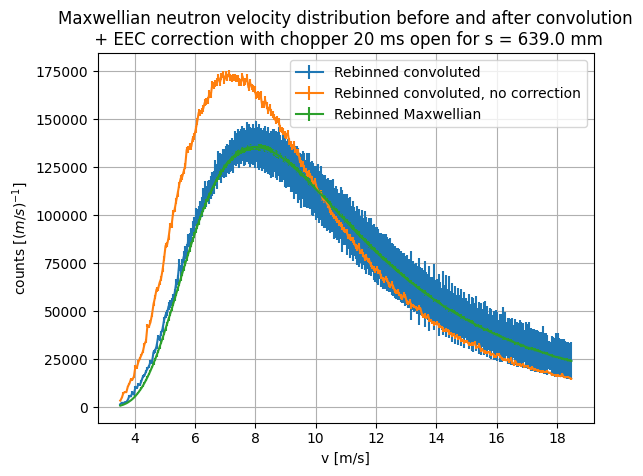

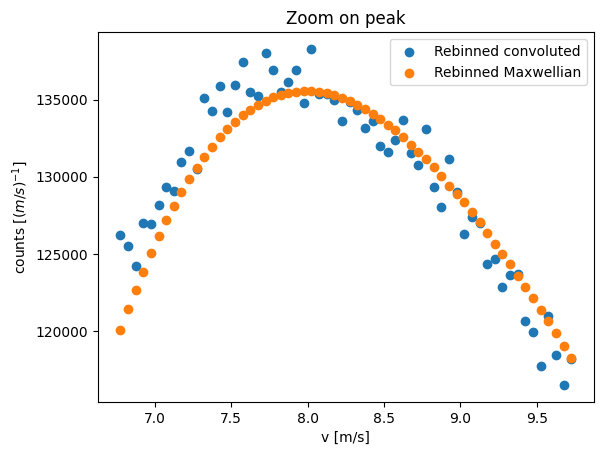

In [72]:

# plot spectra for debug
plt.errorbar(rebinnedTOF_maxwellian_convoluted.v, 
             rebinnedTOF_maxwellian_convoluted.N_v, 
             rebinnedTOF_maxwellian_convoluted.N_v_err,
             label= rebinnedTOF_maxwellian_convoluted.label)
plt.errorbar(rebinnedTOF_maxwellian_convoluted_uncorrected.v, 
             rebinnedTOF_maxwellian_convoluted_uncorrected.N_v, 
             rebinnedTOF_maxwellian_convoluted_uncorrected.N_v_err,
             label= rebinnedTOF_maxwellian_convoluted_uncorrected.label)
plt.errorbar(rebinnedTOF_maxwellian.v,
             rebinnedTOF_maxwellian.N_v,
             rebinnedTOF_maxwellian.N_v_err,
             label= rebinnedTOF_maxwellian.label)
plt.xlabel("v [m/s]")
plt.ylabel(r"counts [$(m/s)^{-1}$]")
plt.legend()
plt.grid(True)
plt.title(f"Maxwellian neutron velocity distribution before and after convolution\n + EEC correction with chopper {chopper1.t_open_ms} ms open for s = {rebinnedTOF_maxwellian.s} mm")
plt.show()

cut1 = 65
cut2 = 125
plt.scatter(rebinnedTOF_maxwellian_convoluted.v[cut1:cut2], 
             rebinnedTOF_maxwellian_convoluted.N_v[cut1:cut2], 
             label= rebinnedTOF_maxwellian_convoluted.label)
plt.scatter(rebinnedTOF_maxwellian.v[cut1:cut2],
             rebinnedTOF_maxwellian.N_v[cut1:cut2],
             label= rebinnedTOF_maxwellian.label)
plt.xlabel("v [m/s]")
plt.ylabel(r"counts [$(m/s)^{-1}$]")
plt.legend()
plt.title("Zoom on peak")
plt.show()

Fit parameters: A=134606.27+-477.92, mean=8.3231+-0.0179, sigma=3.02+-0.04
Fit parameters: A=134672.78+-508.68, mean=8.2095+-0.0211, sigma=3.12+-0.05


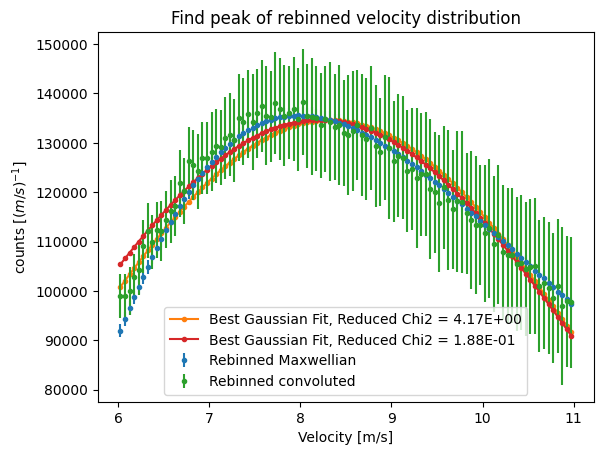

In [73]:
# analyze the pure spectrum and the spectrum after convolution by fitting a gauss to the peak
v_low, v_high = 6.0, 11.0
v_peak_maxwell, v_peak_maxwell_err = rebinnedTOF_maxwellian.find_peak_velocity(gausstype='threepoints', 
                                                                         v_low=v_low, 
                                                                         v_high=v_high, 
                                                                         a0 = 250000.0, 
                                                                         mu0= 8.0, 
                                                                         sigma0=1.0, 
                                                                         do_plot=True, 
                                                                         do_print=True)
v_peak_convoluted, v_peak_convoluted_err = rebinnedTOF_maxwellian_convoluted.find_peak_velocity(gausstype='threepoints', 
                                                                                          v_low=v_low, 
                                                                                          v_high=v_high, 
                                                                                          a0 = 250000.0, 
                                                                                          mu0= 8.0, 
                                                                                          sigma0=1.0, 
                                                                                          do_plot=True, 
                                                                                          do_print=True)

In [74]:
v_mean_maxwell, v_mean_maxwell_err = rebinnedTOF_maxwellian.find_mean_velocity(do_print=True)
#v_mean_convoluted1, v_mean_convoluted_err1 = rebinnedTOF_maxwellian_convoluted.find_mean_velocity(do_print=True, do_newcode=False)
v_mean_convoluted2, v_mean_convoluted_err2 = rebinnedTOF_maxwellian_convoluted.find_mean_velocity(do_print=True, do_newcode=True)

v_rms_maxwell, v_rms_maxwell_err = rebinnedTOF_maxwellian.find_rms_velocity(do_print=True)
v_rms_convoluted, v_rms_convoluted_err = rebinnedTOF_maxwellian_convoluted.find_rms_velocity(do_print=True)

Mean velocity for Rebinned Maxwellian = 10.1815 +- 0.0033 m/s
Mean velocity for Rebinned convoluted = 10.1056 +- 0.0343 m/s
Root mean squared velocity for Rebinned Maxwellian = 10.7145 +- 0.0068 m/s
Root mean squared velocity for Rebinned convoluted = 10.6518 +- 0.0773 m/s


In [75]:
# Analysis of the differences between velocities of original spectrum, convoluted spectrum and convoluted + EEP spectrum

v_mean_difference = np.abs(v_mean_maxwell - v_mean_convoluted2) 
v_mean_sigmas = v_mean_maxwell_err + v_mean_convoluted_err2
v_mean_difference_in_sigmas = v_mean_difference / v_mean_sigmas

print(f"difference of v_means: {v_mean_difference_in_sigmas:.2f} sigma")

difference of v_means: 2.02 sigma
